# Rozdělení Γ a B

*Nad rámec cvičení — oddíly 3.2.7 a 3.2.8 skripta.*

---

Cvičení 4 ukázalo inverzní transformaci, cvičení 5 superpozici a uspořádané výběry, cvičení 6 zamítací metodu. Dvě důležitá rozdělení ale zůstala stranou — a nejsou tam náhodou: **ani u jednoho neumíme invertovat distribuční funkci**. Jsou to přesně ty případy, kdy se vyplatí znát strukturu rozdělení místo vzorce.

- **Γ(a, λ)**: součet exponenciálních veličin (celé $a$), zamítací metoda (obecné $a$)
- **B(a, b)**: uspořádaný výběr (celá $a, b$), podíl dvou gama veličin (obecné)
- jak spolu souvisí a kde se potkáváme s $\chi^2$

Obě rozdělení se v kurzu objeví: $\chi^2$ je speciální případ Γ a používá se v testech generátorů, a B popisuje uspořádané rovnoměrné výběry z cvičení 5.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def estimate(xs):
    """Průměr a jeho směrodatná chyba z hotového seznamu."""
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    print(f"{name}: {mean:.5f} +- {se:.5f}  (přesně {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


def hist_hustota(ax, xs, span, pdf, nazev, bins=60):
    """Histogram ve výšce hustoty s přesnou hustotou červeně."""
    w = (span[1] - span[0]) / bins
    ax.hist(xs, bins=bins, range=span, weights=[1 / (len(xs) * w)] * len(xs), alpha=0.6)
    grid = [span[0] + (span[1] - span[0]) * i / 400 for i in range(401)]
    ax.plot(grid, [pdf(x) for x in grid], "r")
    ax.set_title(nazev, fontsize=10)


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam

## 1. Rozdělení Γ

Hustota $\Gamma(a, \lambda)$ pro $x > 0$ je

$$f(x) = \frac{\lambda^a}{\Gamma(a)}\,x^{a-1}e^{-\lambda x}, \qquad E X = \frac{a}{\lambda}, \qquad D X = \frac{a}{\lambda^2}.$$

Parametr $a > 0$ je **tvar**, $\lambda > 0$ **měřítko**. Speciální případy, které už znáte:

| | |
|---|---|
| $\Gamma(1, \lambda)$ | exponenciální rozdělení $\operatorname{Exp}(\lambda)$ |
| $\Gamma(k, \lambda)$, $k$ celé | Erlangovo — čekání na $k$-tou událost Poissonova procesu |
| $\Gamma(k/2, 1/2)$ | $\chi^2$ o $k$ stupních volnosti |

Distribuční funkce je neúplná gama funkce a **nemá elementární inverzi**, takže inverzní transformace odpadá.

### Celé $a$: součet exponenciál

Pro celé $a = k$ je to snadné. Poissonův proces z cvičení 3: mezery mezi událostmi jsou $\operatorname{Exp}(\lambda)$, takže čas do $k$-té události je součet $k$ z nich. A to je přesně $\Gamma(k, \lambda)$.

Trik: místo $k$ logaritmů stačí **jeden** — součin rovnoměrných čísel.

$$\sum_{i=1}^{k} \left(-\frac{\ln \gamma_i}{\lambda}\right) = -\frac{1}{\lambda}\ln\!\big(\gamma_1\gamma_2\cdots\gamma_k\big).$$

In [2]:
def gamma_cele(k, lam=1.0):
    """Γ(k, λ) pro celé k: jeden logaritmus ze součinu k rovnoměrných čísel."""
    soucin = 1.0
    for _ in range(k):
        soucin *= 1.0 - random.random()     # 1 - γ, aby nikdy nevyšla nula
    return -math.log(soucin) / lam


n = 200_000
for k, lam in ((1, 1.0), (3, 1.0), (5, 2.0)):
    xs = [gamma_cele(k, lam) for _ in range(n)]
    check(f"Γ({k}, {lam}): E X", *estimate(xs), k / lam)
    check(f"Γ({k}, {lam}): D X", *estimate([(x - k / lam) ** 2 for x in xs]), k / lam**2)
    print()

Γ(1, 1.0): E X: 1.00216 +- 0.00224  (přesně 1.00000)
Γ(1, 1.0): D X: 1.00511 +- 0.00636  (přesně 1.00000)

Γ(3, 1.0): E X: 3.00273 +- 0.00388  (přesně 3.00000)
Γ(3, 1.0): D X: 3.00584 +- 0.01335  (přesně 3.00000)

Γ(5, 2.0): E X: 2.49636 +- 0.00250  (přesně 2.50000)
Γ(5, 2.0): D X: 1.25191 +- 0.00501  (přesně 1.25000)



### Obecné $a$: zamítací metoda

Pro necelé $a$ součet nefunguje. Použijeme **Marsagliovu–Tsangovu metodu** (2000) — zamítací metodu z cvičení 6 s chytře zvolenou obálkou.

Myšlenka: pro $a \ge 1$ položíme $d = a - \tfrac13$, $c = 1/\sqrt{9d}$ a generujeme

$$x \sim N(0,1), \qquad v = (1 + c\,x)^3, \qquad \text{kandidát } d\,v .$$

Transformace $v$ je zvolená tak, aby kandidát měl hustotu velmi blízkou cílové; přijímací podmínka pak zamítá jen zřídka (přes 95 % návrhů projde, nezávisle na $a$).

Pro $a < 1$ se použije vztah: je-li $X \sim \Gamma(a+1, 1)$ a $\gamma \sim R(0,1)$ nezávisle, pak $X\,\gamma^{1/a} \sim \Gamma(a, 1)$.

In [3]:
def gamma_obecne(a, lam=1.0):
    """Γ(a, λ) pro libovolné a > 0 (Marsaglia–Tsang)."""
    if a < 1:
        return gamma_obecne(a + 1, lam) * random.random() ** (1.0 / a)
    d = a - 1.0 / 3.0
    c = 1.0 / math.sqrt(9.0 * d)
    while True:
        x = random.gauss(0.0, 1.0)
        v = (1.0 + c * x) ** 3
        if v <= 0:
            continue
        if math.log(1.0 - random.random()) < 0.5 * x * x + d - d * v + d * math.log(v):
            return d * v / lam


def gamma_pdf(a, lam=1.0):
    def f(x):
        if x <= 0:
            return 0.0
        return math.exp(a * math.log(lam) + (a - 1) * math.log(x) - lam * x - math.lgamma(a))
    return f


print(f"{'a':>6s} {'λ':>5s} {'E X':>18s} {'přesně':>9s} {'D X':>18s} {'přesně':>9s}")
for a, lam in ((0.5, 1.0), (2.5, 1.0), (7.3, 2.0)):
    xs = [gamma_obecne(a, lam) for _ in range(n)]
    m, se = estimate(xs)
    v, vse = estimate([(x - a / lam) ** 2 for x in xs])
    print(f"{a:>6.1f} {lam:>5.1f} {m:>11.5f} +- {se:<5.5f} {a / lam:>9.5f} {v:>11.5f} +- {vse:<5.5f} {a / lam**2:>9.5f}")
    assert abs(m - a / lam) < 5 * se and abs(v - a / lam**2) < 5 * vse

# cena: kolik pokusů na jeden vzorek
pokusu = 0
def gamma_s_pocitadlem(a):
    global pokusu
    d = a - 1.0 / 3.0
    c = 1.0 / math.sqrt(9.0 * d)
    while True:
        pokusu += 1
        x = random.gauss(0.0, 1.0)
        v = (1.0 + c * x) ** 3
        if v > 0 and math.log(1.0 - random.random()) < 0.5 * x * x + d - d * v + d * math.log(v):
            return d * v

for a in (1.0, 2.5, 10.0):
    pokusu = 0
    for _ in range(50_000):
        gamma_s_pocitadlem(a)
    print(f"a = {a:>5.1f}: {pokusu / 50_000:.3f} pokusu na vzorek  (přijato {50_000 / pokusu:.1%})")

     a     λ                E X    přesně                D X    přesně
   0.5   1.0     0.49953 +- 0.00157   0.50000     0.49496 +- 0.00406   0.50000
   2.5   1.0     2.49781 +- 0.00353   2.50000     2.49048 +- 0.01158   2.50000
   7.3   2.0     3.65310 +- 0.00302   3.65000     1.82555 +- 0.00678   1.82500
a =   1.0: 1.052 pokusu na vzorek  (přijato 95.0%)
a =   2.5: 1.013 pokusu na vzorek  (přijato 98.7%)
a =  10.0: 1.003 pokusu na vzorek  (přijato 99.7%)


## 2. Rozdělení B

Hustota $B(a, b)$ na $[0, 1]$:

$$f(x) = \frac{x^{a-1}(1-x)^{b-1}}{\mathrm{B}(a,b)}, \qquad E X = \frac{a}{a+b}, \qquad D X = \frac{ab}{(a+b)^2(a+b+1)}.$$

Zvláštní případy: $B(1,1) = R(0,1)$, a hustota $2x$ z cvičení 2 a 4 je $B(2,1)$.

### Celá $a, b$: uspořádaný výběr

Krásná souvislost se cvičením 5. Vezměte $a + b - 1$ nezávislých rovnoměrných čísel a seřaďte je. Pak

$$\gamma_{(a)} \sim B(a, b).$$

Tedy $a$-té nejmenší z $a+b-1$ rovnoměrných čísel má rozdělení $B(a,b)$. Pro $a = n$, $b = 1$ dostaneme maximum, jehož hustota $n x^{n-1}$ je přesně to, co jsme viděli ve cvičení 5.

### Obecná $a, b$: podíl dvou gama veličin

Je-li $X \sim \Gamma(a, 1)$ a $Y \sim \Gamma(b, 1)$ nezávisle, pak

$$\frac{X}{X + Y} \sim B(a, b).$$

Funguje pro libovolná kladná $a, b$ a staví přímo na generátoru z předchozího oddílu.

In [4]:
def beta_poradi(a, b):
    """B(a, b) pro celá a, b: a-té nejmenší z a+b-1 rovnoměrných čísel."""
    cisla = sorted(random.random() for _ in range(a + b - 1))
    return cisla[a - 1]


def beta_podil(a, b):
    """B(a, b) pro libovolná a, b > 0: X / (X + Y), X ~ Γ(a), Y ~ Γ(b)."""
    x = gamma_obecne(a)
    y = gamma_obecne(b)
    return x / (x + y)


def beta_pdf(a, b):
    lnB = math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b)
    def f(x):
        if x <= 0 or x >= 1:
            return 0.0
        return math.exp((a - 1) * math.log(x) + (b - 1) * math.log(1 - x) - lnB)
    return f


print(f"{'a':>5s} {'b':>5s} {'metoda':>12s} {'E X':>10s} {'přesně':>9s} {'D X':>10s} {'přesně':>9s}")
for a, b in ((2, 3), (5, 2)):
    for nazev, gen in (("pořadí", lambda: beta_poradi(a, b)), ("podíl Γ", lambda: beta_podil(a, b))):
        xs = [gen() for _ in range(n)]
        EX = a / (a + b)
        DX = a * b / ((a + b) ** 2 * (a + b + 1))
        m, se = estimate(xs)
        v, _ = estimate([(x - EX) ** 2 for x in xs])
        print(f"{a:>5d} {b:>5d} {nazev:>12s} {m:>10.5f} {EX:>9.5f} {v:>10.5f} {DX:>9.5f}")
        assert abs(m - EX) < 5 * se

# necelé parametry umí jen podíl
a, b = 0.7, 2.4
xs = [beta_podil(a, b) for _ in range(n)]
m, se = estimate(xs)
check(f"B({a}, {b}): E X", m, se, a / (a + b))

    a     b       metoda        E X    přesně        D X    přesně
    2     3       pořadí    0.39919   0.40000    0.04002   0.04000
    2     3      podíl Γ    0.40015   0.40000    0.03995   0.04000
    5     2       pořadí    0.71405   0.71429    0.02545   0.02551
    5     2      podíl Γ    0.71398   0.71429    0.02543   0.02551
B(0.7, 2.4): E X: 0.22617 +- 0.00046  (přesně 0.22581)


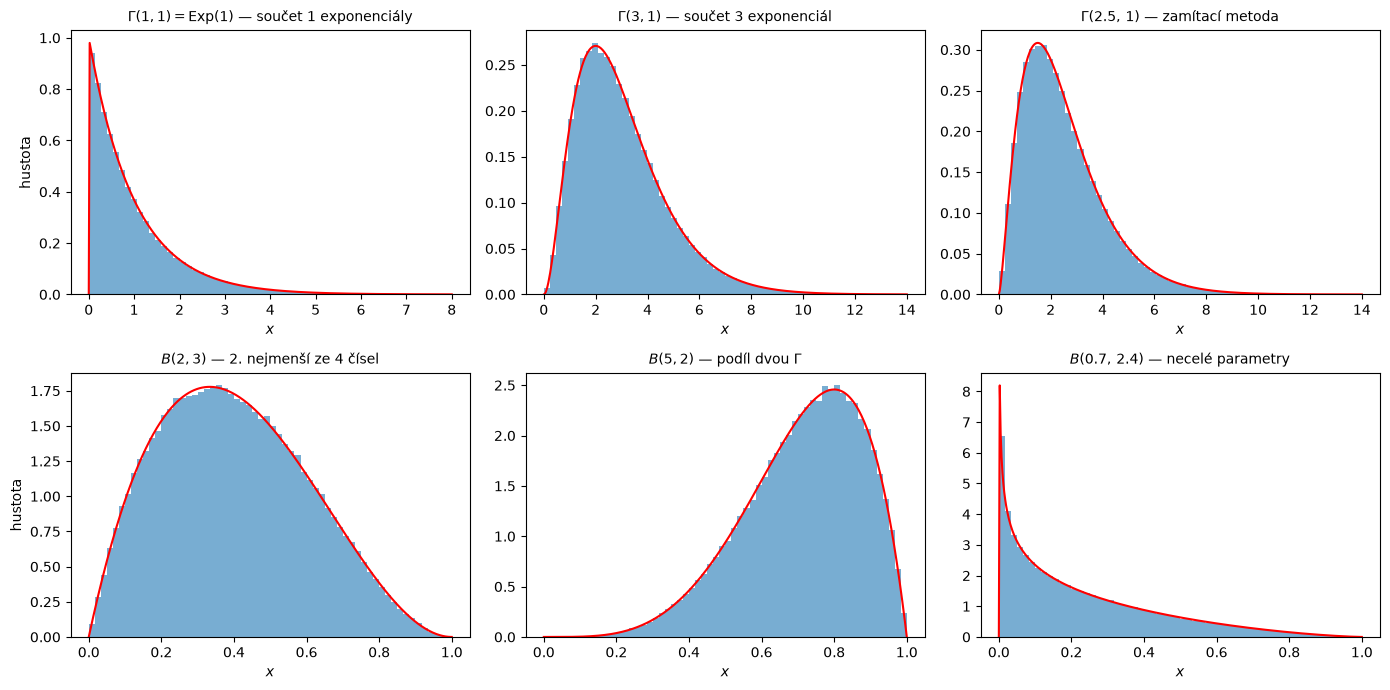

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

hist_hustota(axes[0][0], [gamma_cele(1) for _ in range(n)], (0, 8), gamma_pdf(1),
             r"$\Gamma(1,1) = \mathrm{Exp}(1)$ — součet 1 exponenciály")
hist_hustota(axes[0][1], [gamma_cele(3) for _ in range(n)], (0, 14), gamma_pdf(3),
             r"$\Gamma(3,1)$ — součet 3 exponenciál")
hist_hustota(axes[0][2], [gamma_obecne(2.5) for _ in range(n)], (0, 14), gamma_pdf(2.5),
             r"$\Gamma(2.5,\,1)$ — zamítací metoda")

hist_hustota(axes[1][0], [beta_poradi(2, 3) for _ in range(n)], (0, 1), beta_pdf(2, 3),
             r"$B(2,3)$ — 2. nejmenší ze 4 čísel")
hist_hustota(axes[1][1], [beta_podil(5, 2) for _ in range(n)], (0, 1), beta_pdf(5, 2),
             r"$B(5,2)$ — podíl dvou $\Gamma$")
hist_hustota(axes[1][2], [beta_podil(0.7, 2.4) for _ in range(n)], (0, 1), beta_pdf(0.7, 2.4),
             r"$B(0.7,\,2.4)$ — necelé parametry")

for ax in axes.ravel():
    ax.set_xlabel("$x$")
axes[0][0].set_ylabel("hustota")
axes[1][0].set_ylabel("hustota")
plt.tight_layout()
plt.show()

Všech šest histogramů sedí na hustoty — včetně $B(0.7,\,2.4)$, která v nule diverguje a přesto se generuje bez problémů.

## 3. Souvislost s $\chi^2$

Rozdělení $\chi^2$ o $k$ stupních volnosti, které jsme použili v testech generátorů, je $\Gamma(k/2,\,1/2)$. Ověříme to dvěma nezávislými cestami: součtem čtverců normálních veličin (definice) a naším generátorem Γ.

  k         metoda        E X   přesně        D X   přesně
  1     z definice     1.0012        1     2.0232        2
  1  z Γ(k/2, 1/2)     0.9936        1     1.9693        2
  3     z definice     3.0032        3     6.0044        6
  3  z Γ(k/2, 1/2)     3.0064        3     6.0439        6
 10     z definice    10.0358       10    20.0337       20
 10  z Γ(k/2, 1/2)    10.0251       10    20.1109       20


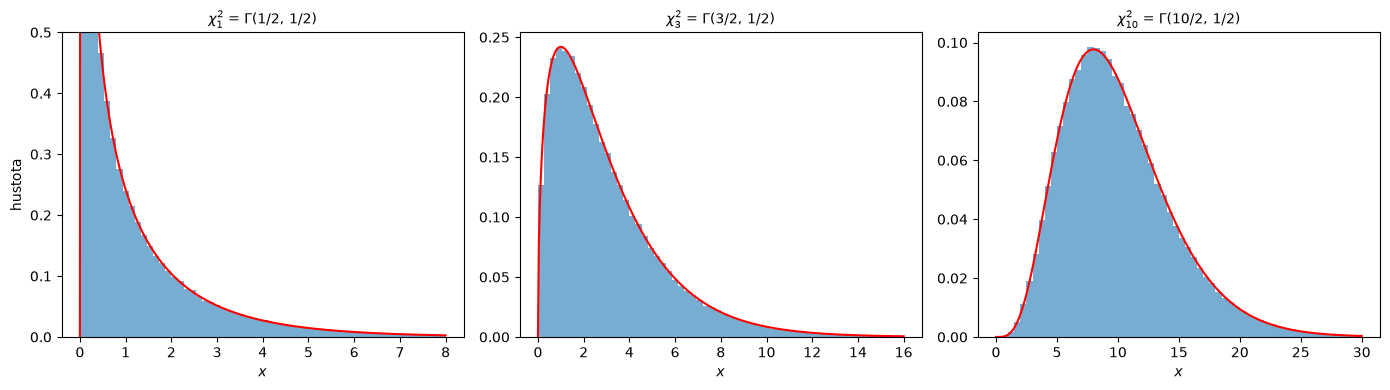

In [6]:
def chi2_z_definice(k):
    """Součet k čtverců nezávislých N(0,1) — definice χ²."""
    return sum(random.gauss(0, 1) ** 2 for _ in range(k))


def chi2_z_gamma(k):
    """Totéž jako Γ(k/2, 1/2) — jedno volání místo k."""
    return gamma_obecne(k / 2.0, 0.5)


print(f"{'k':>3s} {'metoda':>14s} {'E X':>10s} {'přesně':>8s} {'D X':>10s} {'přesně':>8s}")
for k in (1, 3, 10):
    for nazev, gen in (("z definice", lambda: chi2_z_definice(k)), ("z Γ(k/2, 1/2)", lambda: chi2_z_gamma(k))):
        xs = [gen() for _ in range(100_000)]
        m, se = estimate(xs)
        v, _ = estimate([(x - k) ** 2 for x in xs])
        print(f"{k:>3d} {nazev:>14s} {m:>10.4f} {k:>8d} {v:>10.4f} {2 * k:>8d}")
        assert abs(m - k) < 5 * se

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (k, horni) in zip(axes, ((1, 8), (3, 16), (10, 30))):
    xs = [chi2_z_gamma(k) for _ in range(200_000)]
    hist_hustota(ax, xs, (0, horni), gamma_pdf(k / 2, 0.5),
                 f"$\\chi^2_{{{k}}}$ = $\\Gamma({k}/2,\\,1/2)$")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("hustota")
axes[0].set_ylim(0, 0.5)   # hustota χ²_1 v nule diverguje, jinak by ostatní panely zanikly
plt.tight_layout()
plt.show()

## Shrnutí

| Rozdělení | Kdy | Metoda | Cena |
|---|---|---|---|
| $\Gamma(k, \lambda)$, $k$ celé | Erlang, čekání na $k$-tou událost | $-\ln(\gamma_1\cdots\gamma_k)/\lambda$ | $k$ čísel, **jeden** logaritmus |
| $\Gamma(a, \lambda)$, $a$ libovolné | obecný případ | Marsaglia–Tsang, zamítací | ~1.03 pokusu na vzorek |
| $B(a, b)$, celá | uspořádaný výběr | $a$-té nejmenší z $a+b-1$ | $a+b-1$ čísel + třídění |
| $B(a, b)$, libovolná | obecný případ | $X/(X+Y)$, $X\sim\Gamma(a)$, $Y\sim\Gamma(b)$ | dvě volání Γ |
| $\chi^2_k$ | testy | $\Gamma(k/2,\,1/2)$ | jedno volání místo $k$ |

Co si odnést: u obou rozdělení **nejde invertovat $F$**, a přesto se generují snadno — protože známe jejich **strukturu**. Γ je součet exponenciál, B je uspořádaný výběr nebo podíl gam. Hledat strukturu se vyplatí dřív než sahat po numerické inverzi.

### Zkuste si

1. Ověřte, že $\gamma_{(a)}$ z $a+b-1$ čísel má opravdu $B(a,b)$, porovnáním s `beta_podil` pro $(a,b) = (3,4)$.
2. Srovnejte rychlost `gamma_cele(10)` a `gamma_obecne(10)`. Od kterého $k$ se vyplatí zamítací metoda?
3. Pro $a < 1$ má hustota Γ v nule singularitu. Ověřte, že `gamma_obecne(0.3)` ji trefí — porovnejte histogram v log-log měřítku.
4. Vygenerujte $\chi^2_k$ pro $k = 100$ oběma způsoby a změřte čas. Jak roste cena definice a jak cena přes Γ?
5. Dirichletovo rozdělení je zobecnění B: $(X_1,\dots,X_m)/\sum X_i$ s $X_i \sim \Gamma(a_i)$. Vygenerujte ho pro $m = 3$ a ověřte, že složky mají marginálně rozdělení B.
6. Použijte `beta_podil(2, 1)` a ověřte, že dává stejné rozdělení jako $\sqrt{\gamma}$ z cvičení 2 (hustota $2x$).